# Time of the test

Tested in a VDSL network and default parameters

In [3]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import operator as op
warnings.filterwarnings('ignore')

df = pd.read_csv('time_output.csv',
                 parse_dates=["download_duration_s","upload_duration_s","packets_duration_s","test_duration_s"],
                 date_format="%m-%d-%Y %H:%M:%S")

df.head()

,download_duration_s,upload_duration_s,packets_duration_s,test_duration_s
0,55.0,35.0,90.0,90.0
1,55.0,35.0,90.0,90.0
2,55.0,35.0,90.0,90.0
3,55.0,35.0,90.0,90.0
4,55.0,35.0,90.0,90.0


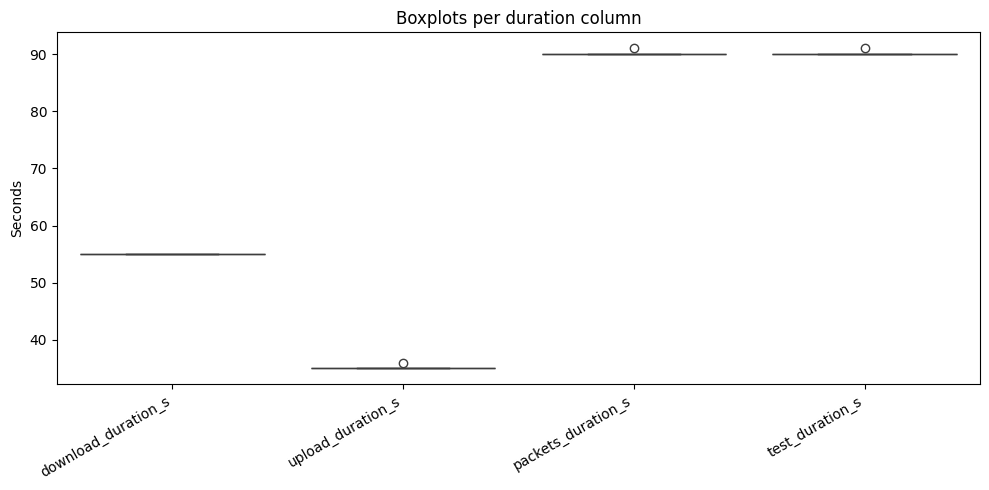

In [4]:
# pick duration columns (adjust if needed)
duration_cols = [c for c in df.columns if c.endswith("_s")]

# force numeric for plotting
plot_df = df[duration_cols].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df)
plt.title("Boxplots per duration column")
plt.ylabel("Seconds")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



In [5]:

# numeric duration data
duration_cols = [c for c in df.columns if c.endswith("_s")]
duration_df = df[duration_cols].apply(pd.to_numeric, errors="coerce")

# stats table
stats = pd.DataFrame({
    "count": duration_df.count(),
    "mean": duration_df.mean(),
    "median": duration_df.median(),
    "std": duration_df.std(ddof=1),
    "variance": duration_df.var(ddof=1),
    "min": duration_df.min(),
    "p25": duration_df.quantile(0.25),
    "p75": duration_df.quantile(0.75),
    "max": duration_df.max(),
    "iqr": duration_df.quantile(0.75) - duration_df.quantile(0.25),
}).round(4)

print("Summary statistics per duration column:")
display(stats)



Summary statistics per duration column:


,count,mean,median,std,variance,min,p25,p75,max,iqr
download_duration_s,50,55.00,55.0,0.0000,0.00,55.0,55.0,55.0,55.0,0.0
upload_duration_s,50,35.02,35.0,0.1414,0.02,35.0,35.0,35.0,36.0,0.0
packets_duration_s,50,90.02,90.0,0.1414,0.02,90.0,90.0,90.0,91.0,0.0
test_duration_s,50,90.02,90.0,0.1414,0.02,90.0,90.0,90.0,91.0,0.0
